# CMiO: standardized versus raw XYZ

Based on **`Experiment_Benchmarks/01_cmio_sc_pacmap_results.ipynb`**. Compare **UMAP + XYZ, PaCMAP + XYZ, and LocalMAP + XYZ** on the same full dataset with algorithm seed **42**. Only the appended coordinate scaling changes; standardized features, algorithm settings, and evaluation stay the same. Standardized coordinates have zero mean and unit variance per axis; raw coordinates retain their original units. 

Embedding neighbourhood: 10. Embedding dimensions: 2. K-means: K=7, 20 initializations, clustering seed 1000+K. Evaluation always uses the same original-coordinate 10-neighbour geometry and standardized feature space.

**Higher is better:** spatial contiguity (%) = 100[1 - (H/N)/log(min(K,10))]; multivariate delineation (%) = 100(1-WCSS/TSS). ARI is supplementary. Entropy measures homogeneity among neighbours, rather than direct agreement with the focal sample. Differences are standardized minus raw, in percentage points for the primary scores. One seed is descriptive and does not establish seed robustness or statistical significance.

Run All for tables and plots. Later change `SEEDS = (42,)` to `tuple(range(30))` and rerun all cells. PaCMAP/LocalMAP retain their normal internal preprocessing, so this tests the actual pipeline input choice.


In [1]:
from __future__ import annotations
from IPython.display import display
import importlib, os, sys, time
from pathlib import Path

# Keep an already imported kernel's Numba pool size; use one active thread.
# On a fresh kernel, configure the pool before numerical imports.
os.environ['NUMBA_NUM_THREADS'] = str(sys.modules['numba'].config.NUMBA_NUM_THREADS) if 'numba' in sys.modules else '1'
import matplotlib.pyplot as plt
import numba, numpy as np, pandas as pd, seaborn as sns
numba.set_num_threads(1)
import pacmap, umap
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.dpi': 120, 'axes.spines.top': False, 'axes.spines.right': False})

def find_root(start=Path.cwd()):
    for candidate in (start.resolve(), *start.resolve().parents):
        if (candidate / 'code' / 'sc_pacmap' / 'sc_pacmap.py').is_file(): return candidate
        nested = candidate / 'sc-pacmap-reproducibility'
        if (nested / 'code' / 'sc_pacmap' / 'sc_pacmap.py').is_file(): return nested
    raise FileNotFoundError('Repository root not found')

ROOT = find_root()
for folder in (ROOT / 'code' / 'sc_pacmap', ROOT / 'code' / 'spasne'):
    sys.path.insert(0, str(folder)) if str(folder) not in sys.path else None
# Keep LocalMAP's Numba resampling reproducible without an external helper file.
import importlib
from contextlib import contextmanager

@numba.njit
def seed_localmap_rng(seed):
    np.random.seed(seed)

@contextmanager
def localmap_seed(seed):
    core = importlib.import_module('pacmap.pacmap')
    original_resample = core.sample_FP_pair_nearby
    call_index = 0
    def seeded_resample(*args, **kwargs):
        nonlocal call_index
        seed_localmap_rng(seed + call_index)
        call_index += 1
        return original_resample(*args, **kwargs)
    seed_localmap_rng(seed)
    core.sample_FP_pair_nearby = seeded_resample
    try:
        yield
    finally:
        core.sample_FP_pair_nearby = original_resample

SEEDS = (42,)
CROSS_GROUP_SEEDS = (42,)
N_NEIGHBORS, N_COMPONENTS, K_REFERENCE = 10, 2, 7
FEATURES = ['Y_PPM','V_PPM','LA_PPM','U_PPM','SR_PPM','SN_PPM','RB_PPM','TH_PPM','CS_PPM','CE_PPM','NB_PPM','GA_PPM','W_PPM','HF_PPM','TA_PPM','ZR_PPM','CR_PPM','PR_PPM','ND_PPM','ER_PPM','EU_PPM','SM_PPM','YB_PPM','TB_PPM','HO_PPM','GD_PPM','DY_PPM','LU_PPM','BA_PPM','SIO2_WT_PERCENT','TIO2_WT_PERCENT','NA2O_WT_PERCENT','K2O_WT_PERCENT','AL2O3_WT_PERCENT','TM_PPM']
data = pd.read_csv(ROOT / 'data' / 'processed' / 'cmio_sc_pacmap_ready.csv')
coords = data[['x','y','z']].to_numpy(float)
truth = data['label_id'].to_numpy(int)
features = StandardScaler().fit_transform(data[FEATURES]).astype(np.float32)
xyz = StandardScaler().fit_transform(coords)
features_xyz = np.column_stack([features, xyz])
tss = float(np.sum((features - features.mean(0, keepdims=True)) ** 2))
spatial_neighbors = NearestNeighbors(n_neighbors=N_NEIGHBORS + 1, n_jobs=1).fit(coords).kneighbors(coords, return_distance=False)[:, 1:]
settings_base = dict(n_components=2, n_neighbors=N_NEIGHBORS, mn_ratio=.5, fp_ratio=2., learning_rate=1., num_iters=(100,100,250), knn_backend='faiss', verbose=False)
from IPython.display import display
import time, json

DATASET_ID = 'cmio'
DATASET_TITLE = 'CMiO'
SOURCE_NOTEBOOK = '01_cmio_sc_pacmap_results.ipynb'

# For the later 30-seed comparison, change SEEDS above to tuple(range(30)).
METHODS = ['UMAP', 'PaCMAP', 'LocalMAP']
SCORE_COLUMNS = ['spatial_contiguity', 'multivariate_delineation', 'ARI']
INPUTS = {'Raw': np.column_stack([features, coords]),
          'Standardized': np.column_stack([features, xyz])}
assert len(SEEDS) == len(set(SEEDS)) and len(SEEDS) > 0
assert np.array_equal(INPUTS['Raw'][:, :features.shape[1]],
                      INPUTS['Standardized'][:, :features.shape[1]])
assert np.isfinite(features).all() and np.isfinite(coords).all()
coordinate_summary = pd.DataFrame({'raw_std': coords.std(axis=0),
                                    'standardized_std': xyz.std(axis=0)},
                                   index=list('XYZ')[:coords.shape[1]])
display(coordinate_summary)
plt.rcParams.update({'figure.dpi': 120, 'axes.spines.top': False, 'axes.spines.right': False})


C:\Users\weihong\Desktop\SC-PACMAP\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,raw_std,standardized_std
X,108089.712091,1.0
Y,362039.209835,1.0
Z,244.095579,1.0


In [2]:

def fit_embedding(method, values, seed):
    args = dict(n_components=2, n_neighbors=N_NEIGHBORS, MN_ratio=.5,
                FP_ratio=2., distance='euclidean', lr=1., num_iters=(100,100,250),
                apply_pca=True, random_state=seed, save_tree=False, knn_backend='faiss')
    if method == 'UMAP':
        return umap.UMAP(n_neighbors=N_NEIGHBORS, n_components=2, metric='euclidean',
                         learning_rate=1., random_state=seed, n_jobs=1).fit_transform(values)
    if method == 'PaCMAP':
        return pacmap.PaCMAP(**args).fit_transform(values, init='pca', save_pairs=False)
    with localmap_seed(seed):
        return pacmap.LocalMAP(**args, low_dist_thres=10).fit_transform(
            np.ascontiguousarray(values, dtype=np.float64), init='pca', save_pairs=False)

# Evaluation functions below are copied unchanged from the source results notebook.
def entropy(labels, neighbors=spatial_neighbors):
    total = 0.
    for n in neighbors:
        counts = np.bincount(labels[n])
        p = counts[counts > 0] / neighbors.shape[1]
        total -= float(np.sum(p * np.log(p)))
    return total / len(labels)

def wcss(labels, k=K_REFERENCE, feature_values=features, total_ss=tss):
    centers = np.vstack([feature_values[labels == j].mean(0) for j in range(k)])
    return float(np.sum((feature_values - centers[labels])**2)) / total_ss

def evaluate(labels, k, feature_values=features, neighbors=spatial_neighbors,
             label_truth=truth, total_ss=tss):
    return {'H_per_sample': entropy(labels, neighbors),
            'WCSS_TSS': wcss(labels, k, feature_values, total_ss),
            'ARI': adjusted_rand_score(label_truth, labels)}

### Fit and score the six paired embeddings

In [3]:

embeddings, clusters, rows = {}, {}, []
for seed in SEEDS:
    for method in METHODS:
        for scaling, values in INPUTS.items():
            start = time.perf_counter()
            embedding = np.asarray(fit_embedding(method, values, seed), dtype=np.float64)
            assert embedding.shape == (len(data), 2) and np.isfinite(embedding).all()
            labels = KMeans(n_clusters=K_REFERENCE, init='k-means++', n_init=20,
                            random_state=1000 + K_REFERENCE).fit_predict(embedding)
            scores = evaluate(labels, K_REFERENCE)
            rows.append(dict(seed=seed, method=method, scaling=scaling, K=K_REFERENCE,
                             n_neighbors=N_NEIGHBORS, **scores,
                             spatial_contiguity=100 * (1 - scores['H_per_sample'] / np.log(
                                 min(K_REFERENCE, spatial_neighbors.shape[1]))),
                             multivariate_delineation=100 * (1 - scores['WCSS_TSS']),
                             seconds=time.perf_counter() - start))
            embeddings[(seed, method, scaling)] = embedding
            clusters[(seed, method, scaling)] = labels
            print(f'{DATASET_TITLE} | seed {seed} | {method} | {scaling}: '
                  f'contiguity {rows[-1]["spatial_contiguity"]:.2f}%, '
                  f'delineation {rows[-1]["multivariate_delineation"]:.2f}%', flush=True)
results = pd.DataFrame(rows)
assert len(results) == len(SEEDS) * len(METHODS) * 2
assert np.isfinite(results[SCORE_COLUMNS].to_numpy()).all()
display(results[['method', 'scaling', 'seed'] + SCORE_COLUMNS].round(3))


C:\Users\weihong\Desktop\SC-PACMAP\.venv\Lib\site-packages\sklearn\manifold\_spectral_embedding.py:324: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(


CMiO | seed 42 | UMAP | Raw: contiguity 97.35%, delineation 3.44%


CMiO | seed 42 | UMAP | Standardized: contiguity 73.54%, delineation 40.86%


CMiO | seed 42 | PaCMAP | Raw: contiguity 99.56%, delineation 15.95%


CMiO | seed 42 | PaCMAP | Standardized: contiguity 72.43%, delineation 40.80%


CMiO | seed 42 | LocalMAP | Raw: contiguity 99.24%, delineation 14.37%


CMiO | seed 42 | LocalMAP | Standardized: contiguity 75.04%, delineation 38.58%


,method,scaling,seed,spatial_contiguity,multivariate_delineation,ARI
0,UMAP,Raw,42,97.349,3.439,0.076
1,UMAP,Standardized,42,73.543,40.856,0.342
2,PaCMAP,Raw,42,99.557,15.950,0.258
3,PaCMAP,Standardized,42,72.430,40.802,0.343
4,LocalMAP,Raw,42,99.245,14.374,0.230
5,LocalMAP,Standardized,42,75.041,38.582,0.354


### Compare scores and paired changes

Scores: higher is better. SD is undefined for one seed.


spatial_contiguity     multivariate_delineation      \
                                    mean std                     mean std   
method   scaling                                                            
UMAP     Raw                      97.349 NaN                    3.439 NaN   
         Standardized             73.543 NaN                   40.856 NaN   
PaCMAP   Raw                      99.557 NaN                   15.950 NaN   
         Standardized             72.430 NaN                   40.802 NaN   
LocalMAP Raw                      99.245 NaN                   14.374 NaN   
         Standardized             75.041 NaN                   38.582 NaN   

                         ARI      
                        mean std  
method   scaling                  
UMAP     Raw           0.076 NaN  
         Standardized  0.342 NaN  
PaCMAP   Raw           0.258 NaN  
         Standardized  0.343 NaN  
LocalMAP Raw           0.230 NaN  
         Standardized  0.354 NaN

Paired change: standardized minus raw; positive favours standardization.


spatial_contiguity     multivariate_delineation        ARI    
                       mean std                     mean std   mean std
method                                                                 
UMAP                -23.806 NaN                   37.417 NaN  0.266 NaN
PaCMAP              -27.127 NaN                   24.853 NaN  0.084 NaN
LocalMAP            -24.204 NaN                   24.208 NaN  0.124 NaN

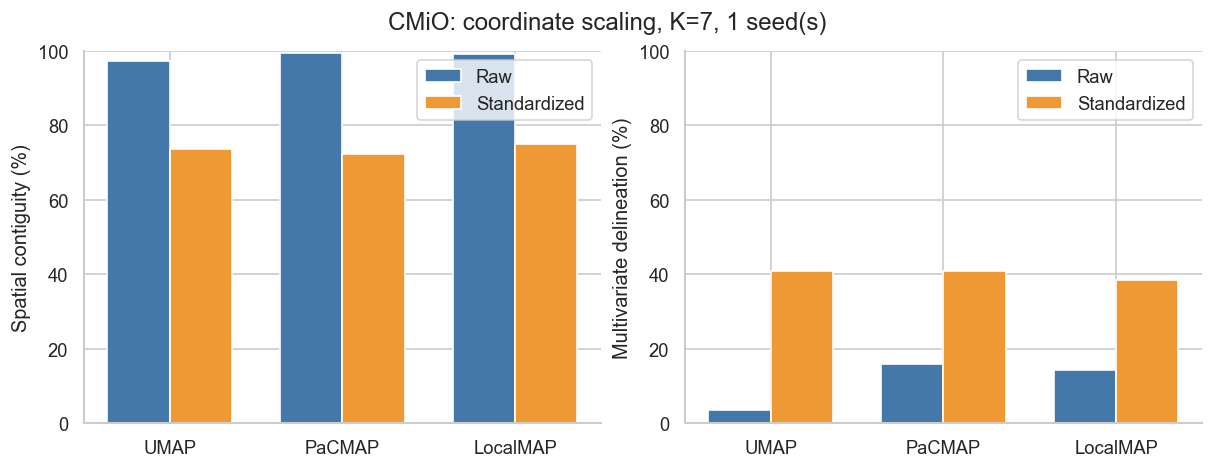

In [4]:

raw = results[results.scaling == 'Raw'].set_index(['seed', 'method'])[SCORE_COLUMNS]
standardized = results[results.scaling == 'Standardized'].set_index(['seed', 'method'])[SCORE_COLUMNS]
paired_differences = (standardized - raw).reset_index()
assert len(paired_differences) == len(SEEDS) * len(METHODS)
score_summary = results.groupby(['method', 'scaling'], sort=False)[SCORE_COLUMNS].agg(['mean', 'std'])
difference_summary = paired_differences.groupby('method', sort=False)[SCORE_COLUMNS].agg(['mean', 'std'])
print('Scores: higher is better. SD is undefined for one seed.')
display(score_summary.round(3))
print('Paired change: standardized minus raw; positive favours standardization.')
display(difference_summary.round(3))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), layout='constrained')
for ax, metric, title in zip(axes, SCORE_COLUMNS[:2],
                            ['Spatial contiguity (%)', 'Multivariate delineation (%)']):
    means = results.groupby(['method', 'scaling'])[metric].mean().unstack().reindex(METHODS)
    x = np.arange(len(METHODS))
    for offset, scaling, color in [(-.18, 'Raw', '#4477AA'), (.18, 'Standardized', '#EE9933')]:
        ax.bar(x + offset, means[scaling], width=.36, label=scaling, color=color)
    ax.set(xticks=x, xticklabels=METHODS, ylabel=title, ylim=(0, 100))
    ax.legend()
fig.suptitle(f'{DATASET_TITLE}: coordinate scaling, K={K_REFERENCE}, {len(SEEDS)} seed(s)')
plt.show()
plt.close(fig)


### Inspect first-seed embeddings
Cluster colours are independent across panels. Axes have arbitrary orientation and scale.

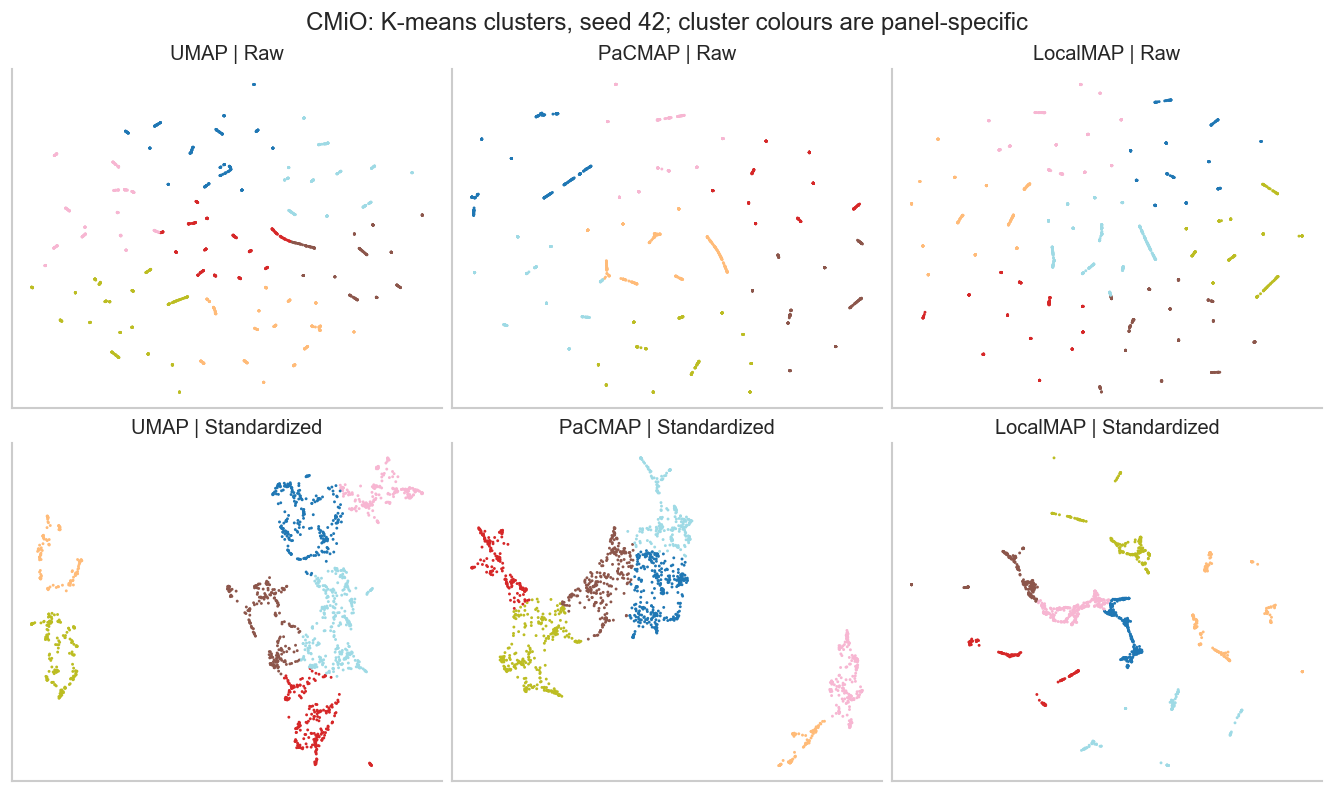

In [5]:

seed = SEEDS[0]
fig, axes = plt.subplots(2, 3, figsize=(11, 6.5), layout='constrained')
for row, scaling in enumerate(INPUTS):
    for col, method in enumerate(METHODS):
        y = embeddings[(seed, method, scaling)]
        axes[row, col].scatter(y[:, 0], y[:, 1], c=clusters[(seed, method, scaling)],
                               cmap='tab20', s=3, linewidths=0, rasterized=True)
        axes[row, col].set(title=f'{method} | {scaling}', xticks=[], yticks=[])
fig.suptitle(f'{DATASET_TITLE}: K-means clusters, seed {seed}; cluster colours are panel-specific')
plt.show()
plt.close(fig)


### Save reproducible results
Exports are separate from the main benchmark results. Reruns replace this dataset's scaling-test exports.

In [6]:

from importlib.metadata import version
EXPORT_DIR = ROOT / 'results' / 'xyz_scaling_test' / DATASET_ID
EXPORT_DIR.mkdir(parents=True, exist_ok=True)
results.to_csv(EXPORT_DIR / 'seed_metrics.csv', index=False)
paired_differences.to_csv(EXPORT_DIR / 'paired_differences.csv', index=False)
score_summary.to_csv(EXPORT_DIR / 'score_summary.csv')
difference_summary.to_csv(EXPORT_DIR / 'difference_summary.csv')
arrays = dict(coordinates=coords, standardized_coordinates=xyz, standardized_features=features,
              spatial_neighbors=spatial_neighbors, truth=truth)
for (seed, method, scaling), y in embeddings.items():
    key = f'{seed}_{method}_{scaling}'
    arrays[f'embedding_{key}'] = y
    arrays[f'clusters_{key}'] = clusters[(seed, method, scaling)]
np.savez_compressed(EXPORT_DIR / 'arrays.npz', **arrays)
metadata = dict(dataset=DATASET_TITLE, source_notebook=SOURCE_NOTEBOOK,
                seeds=list(SEEDS), sample_count=len(data), feature_columns=list(FEATURES),
                coordinate_dimensions=coords.shape[1], n_neighbors=N_NEIGHBORS,
                evaluation_neighbors=spatial_neighbors.shape[1], K=K_REFERENCE,
                kmeans_n_init=20, kmeans_random_state=1000 + K_REFERENCE,
                feature_scaling='StandardScaler, float32; identical in both conditions',
                coordinate_conditions={'Raw': 'original coordinates',
                                       'Standardized': 'StandardScaler per coordinate axis'},
                evaluation='Original-coordinate 10-NN entropy and standardized-feature WCSS/TSS',
                embedding_settings='Same as source results notebook; only coordinate scaling changes',
                packages={p: version(p) for p in ['numpy', 'pandas', 'scikit-learn', 'pacmap', 'umap-learn']})
(EXPORT_DIR / 'metadata.json').write_text(json.dumps(metadata, indent=2), encoding='utf-8')
print(f'Saved results to {EXPORT_DIR}')


Saved results to C:\Users\weihong\Desktop\SC-PACMAP\sc-pacmap-reproducibility\results\xyz_scaling_test\cmio
